## LASSO inflation forecasting

The inflation-only model is:

$$Inflation_t=c+\sum_{k=1}^{6}\phi_k Inflation_{t-k}+error_t$$

The sentiment extension is:

$$Inflation_t=c+\sum_{k=1}^{6}\phi_k Inflation_{t-k}+\sum_{k=1}^{6}\beta_k Sentiment_{t-k}+error_t$$

The second model receives six separate sentiment lags. LASSO can retain useful lags and shrink the others to zero.

In [70]:
# Choose one: 'database' or 'csv'
DATA_SOURCE = 'database'

TEST_START = '2017-01-01'
N_INFLATION_LAGS = 6
N_SENTIMENT_LAGS = 6

In [71]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

search_locations = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    path for path in search_locations if (path / 'README.md').exists()
)
sys.path.insert(0, str(PROJECT_ROOT))
from modelling.config import get_sqlalchemy_engine

CSV_PATH = (
    PROJECT_ROOT / 'data' / 'processed' / 'US' / 'us_macro_2007_2023.csv'
)
RESULTS_DIR = PROJECT_ROOT / 'data' / 'processed' / 'model_results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

LASSO_FORECAST_PATH = RESULTS_DIR / 'lasso_forecasts.csv'
LASSO_METRICS_PATH = RESULTS_DIR / 'lasso_metrics.json'

SAVED_MODEL_FORECASTS = {
    'AR(1)': (RESULTS_DIR / 'ar1_forecasts.csv', 'Forecast'),
    'ARX + sentiment': (RESULTS_DIR / 'arx_forecasts.csv', 'Forecast'),
    'HMM': (RESULTS_DIR / 'hmm_forecasts.csv', 'Forecast'),
    'AR-HMM': (RESULTS_DIR / 'ar_hmm_forecasts.csv', 'Forecast_ARHMM'),
    'AR-HMM + sentiment': (
        RESULTS_DIR / 'ar_hmm_forecasts.csv',
        'Forecast_ARHMM_With_Sentiment',
    ),
}

print('Selected source:', DATA_SOURCE)

Selected source: database


**Load CPI and monthly news sentiment**

In [72]:
if DATA_SOURCE == 'database':
    from sqlalchemy import text

    engine = get_sqlalchemy_engine()
    query = text("""
        SELECT month_date, cpi_value, avg_monthly_sentiment
        FROM analytics.Monthly_Region_Wide_View
        WHERE region_code = 'US'
        ORDER BY month_date
    """)
    raw = pd.read_sql(query, engine, parse_dates=['month_date'])
    raw = raw.rename(columns={
        'month_date': 'Date',
        'cpi_value': 'CPI',
        'avg_monthly_sentiment': 'News_Sentiment',
    })
else:
    raw = pd.read_csv(
        CSV_PATH,
        usecols=['Date', 'CPIAUCSL', 'News_Sentiment'],
        parse_dates=['Date'],
    ).rename(columns={'CPIAUCSL': 'CPI'})

raw = raw.sort_values('Date').drop_duplicates('Date').set_index('Date')
raw['CPI'] = pd.to_numeric(raw['CPI'], errors='coerce')
raw['News_Sentiment'] = pd.to_numeric(
    raw['News_Sentiment'], errors='coerce'
)
print('Rows:', len(raw))
print('Period:', raw.index.min().date(), 'to', raw.index.max().date())

Rows: 204
Period: 2007-01-01 to 2023-12-01


**Create only predictors known before the forecast month**

In [73]:
data = raw.copy()
data['Inflation_MoM'] = data['CPI'].pct_change(1, fill_method=None) * 100

inflation_features = []
for lag in range(1, N_INFLATION_LAGS + 1):
    column = f'Inflation_Lag{lag}'
    data[column] = data['Inflation_MoM'].shift(lag)
    inflation_features.append(column)

sentiment_lag_features = []
for lag in range(1, N_SENTIMENT_LAGS + 1):
    column = f'Sentiment_Lag{lag}'
    data[column] = data['News_Sentiment'].shift(lag)
    sentiment_lag_features.append(column)

sentiment_features = inflation_features + sentiment_lag_features

model_data = data[[
    'Inflation_MoM', *sentiment_features
]].dropna().copy()

test_start = pd.Timestamp(TEST_START)
train = model_data.loc[model_data.index < test_start].copy()
test = model_data.loc[model_data.index >= test_start].copy()

if train.empty or test.empty:
    raise ValueError('TEST_START must leave observations in both periods.')

print('Training period:', train.index.min().date(), 'to', train.index.max().date())
print('Training months:', len(train))
print('Test period:    ', test.index.min().date(), 'to', test.index.max().date())
print('Test months:    ', len(test))

Training period: 2007-08-01 to 2016-12-01
Training months: 113
Test period:     2017-01-01 to 2023-12-01
Test months:     84


**Select the LASSO penalty using training data only**

In [74]:
alpha_grid = np.logspace(-4, 0, 60)
time_series_cv = TimeSeriesSplit(n_splits=5)

def fit_lasso(feature_columns):
    pipeline = Pipeline([
        ('scale', StandardScaler()),
        ('lasso', Lasso(max_iter=100000)),
    ])
    search = GridSearchCV(
        pipeline,
        param_grid={'lasso__alpha': alpha_grid},
        scoring='neg_mean_squared_error',
        cv=time_series_cv,
        n_jobs=-1,
    )
    search.fit(train[feature_columns], train['Inflation_MoM'])
    return search

lasso_inflation_search = fit_lasso(inflation_features)
lasso_sentiment_search = fit_lasso(sentiment_features)

print('Inflation-only selected alpha:',
      lasso_inflation_search.best_params_['lasso__alpha'])
print('Inflation + sentiment selected alpha:',
      lasso_sentiment_search.best_params_['lasso__alpha'])

Inflation-only selected alpha: 0.08227241341700466
Inflation + sentiment selected alpha: 0.07038135554931554


In [75]:
inflation_coefficients = pd.Series(
    lasso_inflation_search.best_estimator_.named_steps['lasso'].coef_,
    index=inflation_features,
    name='LASSO inflation only',
)
sentiment_coefficients = pd.Series(
    lasso_sentiment_search.best_estimator_.named_steps['lasso'].coef_,
    index=sentiment_features,
    name='LASSO inflation + sentiment',
)

coefficient_table = pd.concat([
    inflation_coefficients, sentiment_coefficients
], axis=1).fillna(0.0)
coefficient_table.index.name = 'Standardized predictor'
coefficient_table.round(4)

,LASSO inflation only,LASSO inflation + sentiment
Standardized predictor,,
Inflation_Lag1,0.086,0.0979
Inflation_Lag2,0.000,-0.0000
Inflation_Lag3,-0.000,-0.0000
Inflation_Lag4,-0.000,-0.0000
Inflation_Lag5,-0.000,-0.0000
Inflation_Lag6,-0.000,-0.0000
Sentiment_Lag1,0.000,0.0000
Sentiment_Lag2,0.000,-0.0000
Sentiment_Lag3,0.000,0.0000


**Make one-month-ahead forecasts and compare sentiment**

In [76]:
test['Forecast_LASSO_Inflation'] = (
    lasso_inflation_search.predict(test[inflation_features])
)
test['Forecast_LASSO_Sentiment'] = (
    lasso_sentiment_search.predict(test[sentiment_features])
)

inflation_errors = (
    test['Inflation_MoM'] - test['Forecast_LASSO_Inflation']
)
sentiment_errors = (
    test['Inflation_MoM'] - test['Forecast_LASSO_Sentiment']
)

def error_metrics(errors):
    return {
        'RMSE': float(np.sqrt(np.mean(errors ** 2))),
        'MAE': float(np.mean(np.abs(errors))),
        'Mean Error (Actual - Forecast)': float(np.mean(errors)),
    }

inflation_metrics = error_metrics(inflation_errors)
sentiment_metrics = error_metrics(sentiment_errors)
lasso_metric_comparison = pd.DataFrame.from_dict({
    'LASSO inflation only': inflation_metrics,
    'LASSO inflation + sentiment': sentiment_metrics,
}, orient='index')

print(
    'Sentiment improvement in RMSE:',
    f"{inflation_metrics['RMSE'] - sentiment_metrics['RMSE']:.4f}"
)
print(
    'Sentiment improvement in MAE: ',
    f"{inflation_metrics['MAE'] - sentiment_metrics['MAE']:.4f}"
)
lasso_metric_comparison

Sentiment improvement in RMSE: 0.0051
Sentiment improvement in MAE:  0.0030


,RMSE,MAE,Mean Error (Actual - Forecast)
LASSO inflation only,0.291463,0.209857,0.109276
LASSO inflation + sentiment,0.286343,0.206879,0.103771


**Save both LASSO variants in one CSV and one JSON**

In [77]:
lasso_forecast_output = pd.DataFrame({
    'Date': test.index,
    'Actual': test['Inflation_MoM'].to_numpy(),
    'Forecast_Inflation_Only': (
        test['Forecast_LASSO_Inflation'].to_numpy()
    ),
    'Error_Inflation_Only': inflation_errors.to_numpy(),
    'Forecast_With_Sentiment': (
        test['Forecast_LASSO_Sentiment'].to_numpy()
    ),
    'Error_With_Sentiment': sentiment_errors.to_numpy(),
})
lasso_forecast_output.to_csv(LASSO_FORECAST_PATH, index=False)

def lasso_variant(description, features, metrics, search):
    fitted_lasso = search.best_estimator_.named_steps['lasso']
    return {
        'description': description,
        'features': features,
        'parameters': {
            'alpha': float(search.best_params_['lasso__alpha']),
            'standardized_coefficients': {
                feature: float(value)
                for feature, value in zip(features, fitted_lasso.coef_)
            },
        },
        'metrics': {
            'rmse': metrics['RMSE'],
            'mae': metrics['MAE'],
            'mean_error_actual_minus_forecast': (
                metrics['Mean Error (Actual - Forecast)']
            ),
        },
    }

lasso_metrics_output = {
    'notebook': '06_LASSO',
    'description': 'LASSO variants estimated on the same sample.',
    'data_source': DATA_SOURCE,
    'target': 'Inflation_MoM',
    'forecast_horizon_months': 1,
    'train_start': str(train.index.min().date()),
    'train_end': str(train.index.max().date()),
    'test_start': str(test.index.min().date()),
    'test_end': str(test.index.max().date()),
    'n_train': int(len(train)),
    'n_test': int(len(test)),
    'time_series_cv_splits': int(time_series_cv.n_splits),
    'variants': {
        'inflation_only': lasso_variant(
            'LASSO using historical inflation only.',
            inflation_features, inflation_metrics, lasso_inflation_search
        ),
        'with_sentiment': lasso_variant(
            'LASSO using historical inflation and lagged sentiment.',
            sentiment_features, sentiment_metrics, lasso_sentiment_search
        ),
    },
}
with LASSO_METRICS_PATH.open('w', encoding='utf-8') as file:
    json.dump(lasso_metrics_output, file, indent=2)

print('Saved combined forecasts:', LASSO_FORECAST_PATH)
print('Saved combined metrics:  ', LASSO_METRICS_PATH)

Saved combined forecasts: d:\Master Semester 4\Thesis\data\processed\model_results\lasso_forecasts.csv
Saved combined metrics:   d:\Master Semester 4\Thesis\data\processed\model_results\lasso_metrics.json


## Compare every implemented forecasting model

In [78]:
missing_files = sorted({
    str(path)
    for path, forecast_column in SAVED_MODEL_FORECASTS.values()
    if not path.exists()
})
if missing_files:
    raise FileNotFoundError(
        'Run Parts 02 through 05 first. Missing files: ' + str(missing_files)
    )

forecast_frames = {}
for model_name, (path, forecast_column) in SAVED_MODEL_FORECASTS.items():
    saved = pd.read_csv(path, parse_dates=['Date']).set_index('Date')
    if forecast_column not in saved.columns:
        raise ValueError(
            f'Missing column {forecast_column!r} in {path.name}. '
            'Rerun the notebook that owns this result file.'
        )
    forecast_frames[model_name] = saved[[
        'Actual', forecast_column
    ]].rename(columns={forecast_column: 'Forecast'})

forecast_frames['LASSO inflation only'] = pd.DataFrame({
    'Actual': test['Inflation_MoM'],
    'Forecast': test['Forecast_LASSO_Inflation'],
})
forecast_frames['LASSO inflation + sentiment'] = pd.DataFrame({
    'Actual': test['Inflation_MoM'],
    'Forecast': test['Forecast_LASSO_Sentiment'],
})

common_dates = test.index
for frame in forecast_frames.values():
    common_dates = common_dates.intersection(frame.index)
common_dates = common_dates.sort_values()

if len(common_dates) == 0:
    raise ValueError('The saved models have no common test dates.')

actual_reference = test['Inflation_MoM'].reindex(common_dates)
comparison_metrics = {}
for model_name, frame in forecast_frames.items():
    aligned = frame.reindex(common_dates)
    if not np.allclose(aligned['Actual'], actual_reference):
        raise ValueError(f'Actual inflation differs for saved model: {model_name}')
    errors = actual_reference - aligned['Forecast']
    comparison_metrics[model_name] = error_metrics(errors)

model_comparison = pd.DataFrame.from_dict(
    comparison_metrics, orient='index'
).sort_values('RMSE')
model_comparison.index.name = 'Model'

comparison_summary = {
    'common_test_start': str(common_dates.min().date()),
    'common_test_end': str(common_dates.max().date()),
    'n_common_test_months': int(len(common_dates)),
    'metrics': {
        model: {
            'rmse': values['RMSE'],
            'mae': values['MAE'],
            'mean_error_actual_minus_forecast': (
                values['Mean Error (Actual - Forecast)']
            ),
        }
        for model, values in comparison_metrics.items()
    },
}
lasso_metrics_output['all_model_common_sample_comparison'] = (
    comparison_summary
)
with LASSO_METRICS_PATH.open('w', encoding='utf-8') as file:
    json.dump(lasso_metrics_output, file, indent=2)

print('Common test months:', len(common_dates))
print('Comparison added to:', LASSO_METRICS_PATH)
model_comparison

Common test months: 84
Comparison added to: d:\Master Semester 4\Thesis\data\processed\model_results\lasso_metrics.json


,RMSE,MAE,Mean Error (Actual - Forecast)
Model,,,
AR(1),0.265153,0.195604,0.067525
ARX + sentiment,0.266704,0.196726,0.065917
AR-HMM,0.269457,0.196073,0.074375
LASSO inflation + sentiment,0.286343,0.206879,0.103771
LASSO inflation only,0.291463,0.209857,0.109276
AR-HMM + sentiment,0.300815,0.213690,0.088730
HMM,0.331266,0.235046,0.128187


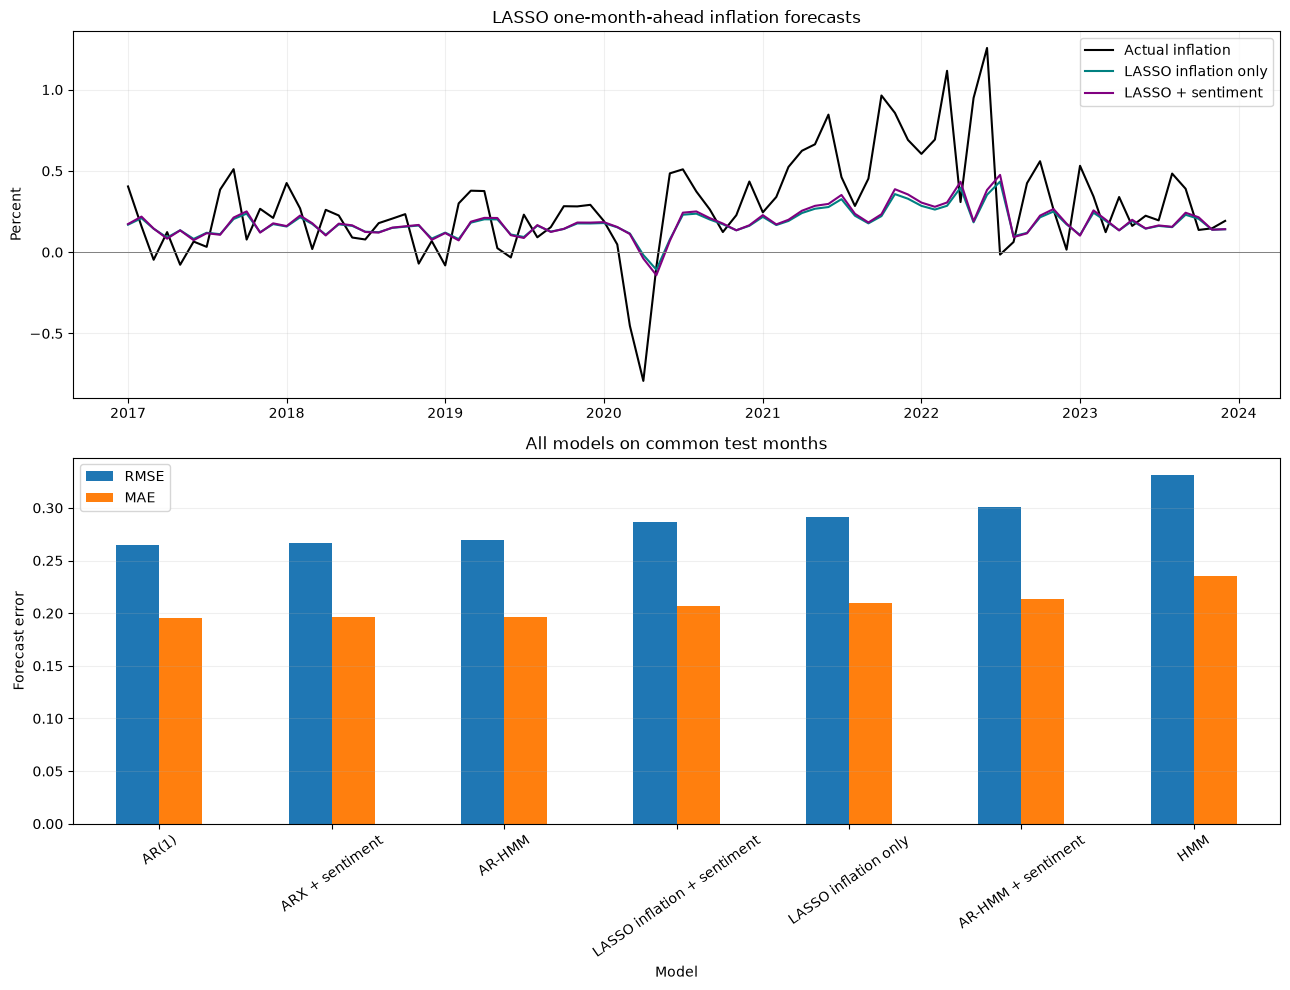

In [79]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10))

axes[0].plot(test.index, test['Inflation_MoM'],
             label='Actual inflation', color='black')
axes[0].plot(test.index, test['Forecast_LASSO_Inflation'],
             label='LASSO inflation only', color='teal')
axes[0].plot(test.index, test['Forecast_LASSO_Sentiment'],
             label='LASSO + sentiment', color='purple')
axes[0].axhline(0, color='gray', linewidth=0.7)
axes[0].set_title('LASSO one-month-ahead inflation forecasts')
axes[0].set_ylabel('Percent')
axes[0].legend()
axes[0].grid(alpha=0.2)

model_comparison[['RMSE', 'MAE']].plot.bar(ax=axes[1])
axes[1].set_title('All models on common test months')
axes[1].set_ylabel('Forecast error')
axes[1].tick_params(axis='x', rotation=35)
axes[1].grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()